# Listening Behaviour Analysis: what drives skips, and which artists stick?

**Data:** my Spotify Extended Streaming History, July 2019 – November 2026, modelled by the dbt
project in this repo (`marts.marts_fct_stream_events`, `marts.marts_dim_listening_sessions`).
All analysis runs SQL directly against the DuckDB warehouse.

**Business framing.** Treating myself (a spotify listener) as a product's user base in miniature. A streaming
service cares about three things this data can speak to:

1. **Engagement:** how is listening volume trending?
2. **Satisfaction:** what predicts a skip (the clearest negative signal a listener gives)?
3. **Retention:** when a new artist is discovered, what predicts whether they're still played months later?

Plus one **anomaly investigation**: explicit skipping roughly doubled in 2026. Why?

> **Scope & limits.** This is one listener (n = 1 person, ~108k plays). Findings describe *my*
> behaviour and are not generalisable to Spotify's user base; they demonstrate the analytical method.
> 2019 and 2026 are partial years. Spotify's logging can change between app versions.

In [2]:
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from pathlib import Path

con = duckdb.connect("../spotify_analytics.duckdb", read_only=True)
sql = lambda q: con.sql(q).df()
FIG = Path("../docs/analysis"); FIG.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e7e6e1"
BLUE, BLUE_LIGHT, ORANGE = "#2a78d6", "#86b6ef", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10.5, "lines.linewidth": 2, "figure.dpi": 110,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight"); plt.show()

def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

## Definitions

| Metric | Definition |
|---|---|
| **Play** | one music stream event (podcasts excluded below) |
| **Explicit skip** | next button pressed within 30 s (`skip_type = 'Explicit Skip'`) |
| **Early rejection** | *any* deliberate abandonment within 30 s: next button, back button, or choosing another song |
| **Qualified stream** | play ≥ 30 s (Spotify's own stream-count rule) |
| **Session** | plays separated by < 15 min of silence (built in the dbt sessionization model) |

## 1. Engagement: how has listening volume changed?

In [3]:
yearly = sql('''
    select
        year(event_date)                                        as year,
        min(event_date)                                         as first_day,
        max(event_date)                                         as last_day,
        count(*)                                                as plays,
        count(distinct session_id)                              as sessions,
        round(sum(duration_played_sec) / 3600, 0)               as hours,
        round(avg(is_complete_listen::int) * 100, 1)            as completion_rate_pct,
        round(avg(is_explicit_skip::int) * 100, 1)              as explicit_skip_rate_pct
    from marts.marts_fct_stream_events
    where content_type = 'music'
    group by 1
    order by 1
''')
# partial years: annualise hours by days covered
yearly["days_covered"] = (pd.to_datetime(yearly.last_day) - pd.to_datetime(yearly.first_day)).dt.days + 1
yearly["is_partial"] = yearly.days_covered < 360
yearly["hours_annualised"] = (yearly.hours * 365 / yearly.days_covered).round(0)
yearly["yoy_change_pct"] = (yearly.hours_annualised.pct_change() * 100).round(1)
yearly

,year,first_day,last_day,plays,sessions,hours,completion_rate_pct,explicit_skip_rate_pct,days_covered,is_partial,hours_annualised,yoy_change_pct
0,2019,2019-07-22,2019-12-31,7651,561,361.0,62.7,6.9,163,True,808.0,NaN
1,2020,2020-01-01,2020-12-31,16497,1272,677.0,50.2,12.6,366,False,675.0,-16.5
2,2021,2021-01-01,2021-12-31,12335,1159,545.0,53.5,8.7,365,False,545.0,-19.3
3,2022,2022-01-01,2022-12-31,16766,1470,833.0,62.7,9.2,365,False,833.0,52.8
4,2023,2023-01-01,2023-12-31,16463,1406,931.0,67.8,8.6,365,False,931.0,11.8
5,2024,2024-01-01,2024-12-31,13902,1246,760.0,69.9,7.9,366,False,758.0,-18.6
6,2025,2025-01-01,2025-12-31,12666,1274,654.0,62.9,9.0,365,False,654.0,-13.7
7,2026,2026-01-01,2026-11-10,11585,1090,567.0,58.5,19.9,314,True,659.0,0.8


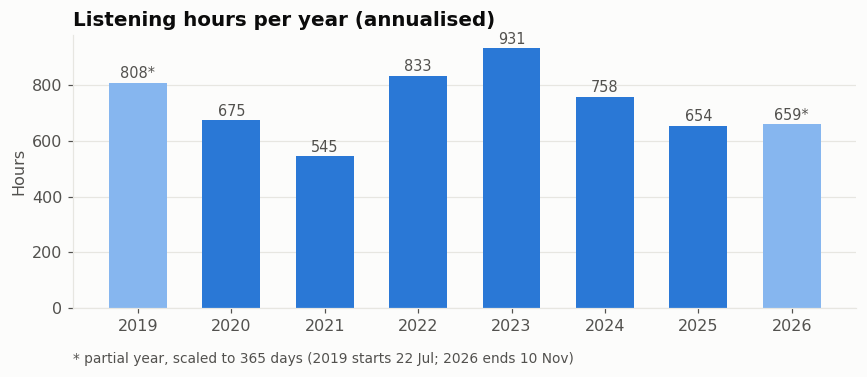

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE_LIGHT if p else BLUE for p in yearly.is_partial]
bars = ax.bar(yearly.year.astype(str), yearly.hours_annualised, color=colors, width=0.62)
for b, (_, r) in zip(bars, yearly.iterrows()):
    label = f"{int(r.hours_annualised):,}" + ("*" if r.is_partial else "")
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 15, label, ha="center", color=INK2, fontsize=9.5)
ax.set_title("Listening hours per year (annualised)")
ax.set_ylabel("Hours"); ax.grid(axis="x", visible=False)
ax.text(0, -0.2, "* partial year, scaled to 365 days (2019 starts 22 Jul; 2026 ends 10 Nov)",
        transform=ax.transAxes, color=INK2, fontsize=9)
save(fig, "q1_hours_per_year")

In [5]:
peak = yearly.loc[yearly.hours_annualised.idxmax()]
print(f"Peak year: {int(peak.year)} with {int(peak.hours_annualised):,} hours")
for _, r in yearly[yearly.year >= 2024].iterrows():
    print(f"{int(r.year)}: {int(r.hours_annualised):,} h annualised ({r.yoy_change_pct:+.1f}% YoY)")

Peak year: 2023 with 931 hours
2024: 758 h annualised (-18.6% YoY)
2025: 654 h annualised (-13.7% YoY)
2026: 659 h annualised (+0.8% YoY)


**Finding.** Listening peaked in 2023 (931 hours), fell 30% to 654 hours by 2025, and has
levelled off in 2026 (659 hours annualised, +0.8%). Sessions fell far less over the same period
(1,406 → 1,274, −9%), so most of the decline is in *how long* each session lasts, not *how often* I listen.

## 2. Satisfaction: what drives a skip?

Several candidate drivers overlap (e.g. shuffle is on for >90% of plays, and long sessions are
mostly shuffled), so raw comparisons can mislead. Approach:

1. Build one row per play with candidate drivers in SQL.
2. Check the strongest raw pattern (position in session) with a **composition-controlled** view.
3. Fit a **logistic regression** for each skip definition, with standard errors **clustered by
   session** (plays within a session are not independent) and year fixed effects (to absorb logging drift).

In [6]:
plays = sql('''
    select
        session_id,
        is_explicit_skip::int                                              as explicit_skip,
        ((duration_played_sec < 30)
            and skip_type in ('Explicit Skip', 'Partial Listen'))::int     as early_rejection,
        least(event_seq_in_session, 30)                                    as position,
        is_shuffle::int                                                    as shuffle,
        -- first time this exact track appears in my history
        (row_number() over (partition by artist_name, track_name
                            order by stream_start_ts) = 1)::int            as first_listen,
        (day_type = 'Weekend')::int                                        as weekend,
        daypart,
        year(event_date)::varchar                                          as year
    from marts.marts_fct_stream_events
    where content_type = 'music'
''')
print(f"{len(plays):,} plays | explicit skip rate {plays.explicit_skip.mean():.1%} | "
      f"early rejection rate {plays.early_rejection.mean():.1%}")

107,865 plays | explicit skip rate 10.4% | early rejection rate 20.2%


### 2a. Skip fatigue, controlled for session composition

Raw skip rate rises with position, but only long sessions reach position 20, so the raw curve
mixes "later in a session" with "a different kind of session". Restricting to sessions with
**at least 20 tracks** means every position is computed over the *same* sessions.

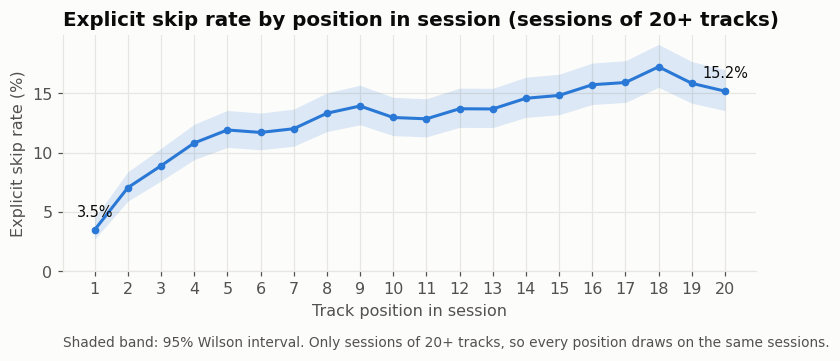

In [7]:
fatigue = sql('''
    select
        f.event_seq_in_session                      as position,
        count(*)                                    as plays,
        sum(f.is_explicit_skip::int)                as skips
    from marts.marts_fct_stream_events as f
    join marts.marts_dim_listening_sessions as d using (session_id)
    where f.content_type = 'music'
      and d.total_tracks_played >= 20            -- fixed set of sessions
      and f.event_seq_in_session <= 20
    group by 1
    order by 1
''')
fatigue["rate"] = fatigue.skips / fatigue.plays
fatigue["lo"], fatigue["hi"] = wilson(fatigue.skips, fatigue.plays)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(fatigue.position, fatigue.lo * 100, fatigue.hi * 100, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(fatigue.position, fatigue.rate * 100, color=BLUE, marker="o", markersize=4)
for pos in (1, 20):
    r = fatigue[fatigue.position == pos].iloc[0]
    ax.annotate(f"{r.rate:.1%}", (pos, r.rate * 100), textcoords="offset points", xytext=(0, 9),
                ha="center", color=INK, fontsize=9.5)
ax.set_title("Explicit skip rate by position in session (sessions of 20+ tracks)")
ax.set_xlabel("Track position in session"); ax.set_ylabel("Explicit skip rate (%)")
ax.set_xticks(range(1, 21, 1)); ax.set_ylim(0, None)
ax.text(0, -0.32, "Shaded band: 95% Wilson interval. Only sessions of 20+ tracks, so every position draws on the same sessions.",
        transform=ax.transAxes, color=INK2, fontsize=9)
save(fig, "q2a_skip_fatigue")

In [8]:
early, late = fatigue[fatigue.position <= 5], fatigue[fatigue.position.between(16, 20)]
table = np.array([[early.skips.sum(), early.plays.sum() - early.skips.sum()],
                  [late.skips.sum(),  late.plays.sum()  - late.skips.sum()]])
chi2, p, _, _ = stats.chi2_contingency(table)
print(f"Tracks 1-5:   {early.skips.sum() / early.plays.sum():.1%} explicit skip rate")
print(f"Tracks 16-20: {late.skips.sum() / late.plays.sum():.1%} explicit skip rate")
print(f"Chi-square = {chi2:.1f}, p = {p:.2g}")

Tracks 1-5:   8.4% explicit skip rate
Tracks 16-20: 16.0% explicit skip rate
Chi-square = 220.0, p = 9.2e-50


### 2b. Logistic regression: separating the drivers

In [9]:
plays["log_position"] = np.log(plays.position)
FORMULA = ("{y} ~ log_position + shuffle + first_listen + weekend"
           " + C(daypart, Treatment('Afternoon')) + C(year)")
groups = plays.session_id.astype("category").cat.codes

def fit(y):
    m = smf.logit(FORMULA.format(y=y), data=plays).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": groups})
    ci = m.conf_int()
    rows = {
        "Position (per doubling)": ("log_position", np.log(2)),
        "Shuffle on":              ("shuffle", 1),
        "First listen of track":   ("first_listen", 1),
        "Weekend":                 ("weekend", 1),
        "Evening (vs afternoon)":  ("C(daypart, Treatment('Afternoon'))[T.Evening]", 1),
        "Late night (vs afternoon)": ("C(daypart, Treatment('Afternoon'))[T.Late Night]", 1),
        "Morning (vs afternoon)":  ("C(daypart, Treatment('Afternoon'))[T.Morning]", 1),
    }
    out = pd.DataFrame([{
        "driver": k,
        "odds_ratio": np.exp(m.params[v] * s),
        "ci_low": np.exp(ci.loc[v, 0] * s),
        "ci_high": np.exp(ci.loc[v, 1] * s),
        "p_value": m.pvalues[v],
    } for k, (v, s) in rows.items()])
    print(f"{y}: n = {int(m.nobs):,}, pseudo-R² = {m.prsquared:.3f}")
    return out.round(3)

or_explicit = fit("explicit_skip")
or_early = fit("early_rejection")
pd.concat({"Explicit skip": or_explicit.set_index("driver"),
           "Early rejection": or_early.set_index("driver")}, axis=1)

explicit_skip: n = 107,865, pseudo-R² = 0.057
early_rejection: n = 107,865, pseudo-R² = 0.050


Explicit skip                         \
                             odds_ratio ci_low ci_high p_value   
driver                                                           
Position (per doubling)           1.464  1.405   1.525   0.000   
Shuffle on                        1.837  1.388   2.431   0.000   
First listen of track             1.019  0.760   1.367   0.898   
Weekend                           1.033  0.873   1.222   0.707   
Evening (vs afternoon)            1.221  1.040   1.435   0.015   
Late night (vs afternoon)         1.081  0.851   1.373   0.526   
Morning (vs afternoon)            1.086  0.890   1.325   0.415   

                          Early rejection                         
                               odds_ratio ci_low ci_high p_value  
driver                                                            
Position (per doubling)             1.172  1.136   1.209   0.000  
Shuffle on                          1.059  0.920   1.220   0.422  
First listen of track               1.813  1.591   2.065   0.000  
Weekend                             1.114  0.985   1.260   0.085  
Evening (vs afternoon)              1.092  0.970   1.229   0.145  
Late night (vs afternoon)           1.265  1.076   1.487   0.004  
Morning (vs afternoon)              0.912  0.775   1.073   0.268

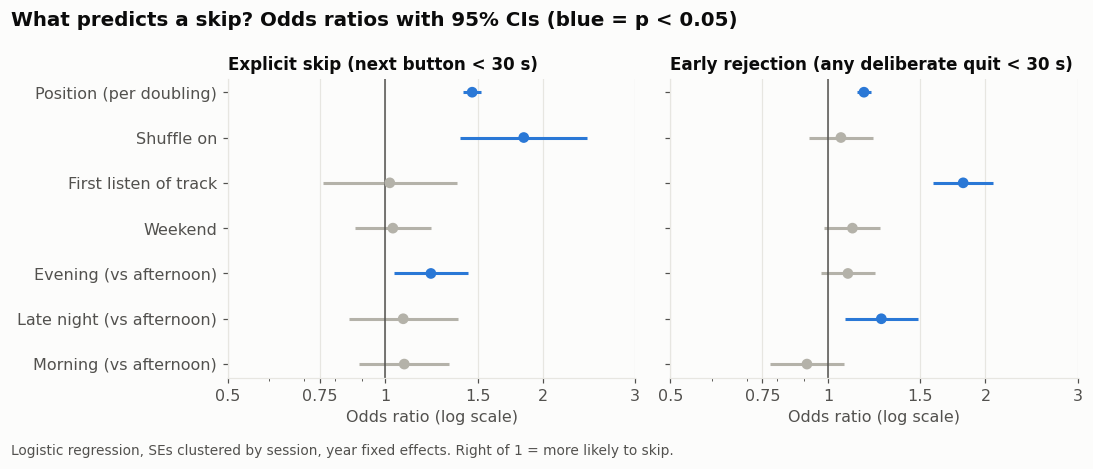

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (title, df) in zip(axes, [("Explicit skip (next button < 30 s)", or_explicit),
                                   ("Early rejection (any deliberate quit < 30 s)", or_early)]):
    y = np.arange(len(df))[::-1]
    sig = df.p_value < 0.05
    ax.hlines(y, df.ci_low, df.ci_high, color=np.where(sig, BLUE, "#b4b2a9"), linewidth=2)
    ax.scatter(df.odds_ratio, y, color=np.where(sig, BLUE, "#b4b2a9"), s=36, zorder=3)
    ax.axvline(1, color=INK2, linewidth=1)
    ax.set_xscale("log"); ax.set_xlim(0.5, 3)
    ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(title, fontsize=11); ax.set_xlabel("Odds ratio (log scale)"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(or_explicit))[::-1]); axes[0].set_yticklabels(or_explicit.driver)
fig.suptitle("What predicts a skip? Odds ratios with 95% CIs (blue = p < 0.05)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Logistic regression, SEs clustered by session, year fixed effects. "
         "Right of 1 = more likely to skip.", color=INK2, fontsize=9)
save(fig, "q2b_skip_drivers")

**Findings.**

* **Fatigue is the most consistent driver.** Within the same long sessions, the explicit skip rate
  roughly doubles from tracks 1–5 (8.4%) to tracks 16–20 (16.0%; χ² p < 0.001). In the regression,
  each doubling of position raises explicit-skip odds by 46% and early-rejection odds by 17%.
  It holds under both definitions, controlling for shuffle, time of day and year.
* **The metric definition changes the story.** Shuffle raises *explicit* skip odds by 84% but has
  no significant effect on *early rejection* overall, which suggests shuffle changes *how* I reject a song
  (next button vs. choosing another) more than *whether* I do. Conversely, a track's **first listen**
  has no effect on next-button skips (OR 1.02, n.s.) but raises early-rejection odds by 81%: new songs
  get abandoned, just not via the button. Late-night listening also raises early rejection (+27%).
* **Implication:** a "skip rate" KPI built on the next button alone would *understate* how often
  new music is rejected, and *overstate* the cost of shuffle.

## 3. Retention: which newly discovered artists stick?

**Cohort definition.** An artist's cohort is the month of their first qualified stream (≥ 30 s).
They are **retained** if they get at least one qualified stream 6–12 months later.

* Cohorts from **Jan 2020 – Oct 2025** only. 2019 is excluded because the export starts mid-2019,
  so long-time favourites would masquerade as 2019 "discoveries" (left-censoring). Cohorts after Oct 2025 have
  less than 12 months of follow-up (right-censoring).

In [11]:
cohorts = sql('''
    with monthly as (            -- qualified streams per artist per month
        select artist_name, date_trunc('month', event_date) as month, count(*) as streams
        from marts.marts_fct_stream_events
        where content_type = 'music' and is_qualified_stream
        group by 1, 2
    ),
    first_month as (             -- cohort = first month with a qualified stream
        select artist_name, min(month) as cohort_month
        from monthly
        group by 1
    ),
    cohort_stats as (
        select
            f.artist_name,
            f.cohort_month,
            max(case when m.month = f.cohort_month then m.streams end)               as first_month_streams,
            max((date_diff('month', f.cohort_month, m.month) between 6 and 12)::int) as retained_6_12m
        from first_month as f
        join monthly as m using (artist_name)
        where f.cohort_month between date '2020-01-01' and date '2025-10-01'
        group by 1, 2
    )
    select
        case when first_month_streams = 1 then '1'
             when first_month_streams <= 3 then '2-3'
             when first_month_streams <= 9 then '4-9'
             else '10+' end                                      as first_month_streams,
        count(*)                                                 as artists,
        sum(retained_6_12m)                                      as retained
    from cohort_stats
    group by 1
    order by min(first_month_streams)
''')
cohorts["retention_rate"] = cohorts.retained / cohorts.artists
cohorts["lo"], cohorts["hi"] = wilson(cohorts.retained, cohorts.artists)
chi2, p, dof, _ = stats.chi2_contingency(np.c_[cohorts.retained, cohorts.artists - cohorts.retained])
print(f"{cohorts.artists.sum():,} artists discovered Jan 2020 - Oct 2025 | chi-square = {chi2:.1f}, dof = {dof}, p = {p:.2g}")
cohorts.round(3)

1,078 artists discovered Jan 2020 - Oct 2025 | chi-square = 167.9, dof = 3, p = 3.6e-36


,first_month_streams,artists,retained,retention_rate,lo,hi
0,1,604,98.0,0.162,0.135,0.194
1,2-3,227,74.0,0.326,0.268,0.389
2,4-9,157,88.0,0.561,0.482,0.636
3,10+,90,61.0,0.678,0.576,0.765


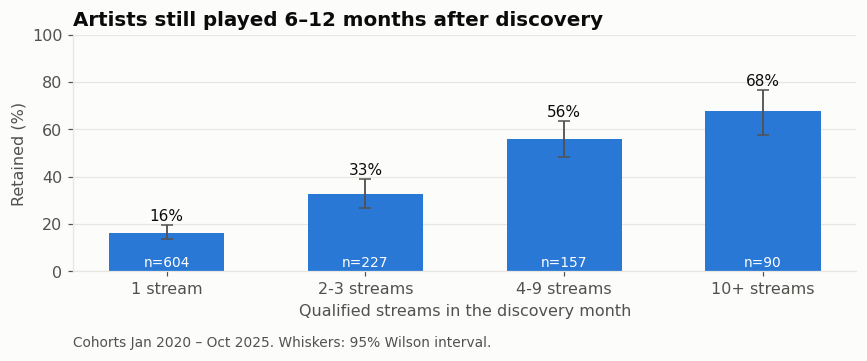

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(cohorts))
bars = ax.bar(x, cohorts.retention_rate * 100, color=BLUE, width=0.58)
ax.errorbar(x, cohorts.retention_rate * 100,
            yerr=[(cohorts.retention_rate - cohorts.lo) * 100, (cohorts.hi - cohorts.retention_rate) * 100],
            fmt="none", ecolor=INK2, elinewidth=1.2, capsize=4)
for i, r in cohorts.iterrows():
    ax.text(i, r.hi * 100 + 2, f"{r.retention_rate:.0%}", ha="center", color=INK, fontsize=10)
    ax.text(i, 2, f"n={r.artists}", ha="center", color="white", fontsize=9)
ax.set_xticks(x, [f"{b} stream{'s' if b != '1' else ''}" for b in cohorts.first_month_streams])
ax.set_title("Artists still played 6–12 months after discovery")
ax.set_xlabel("Qualified streams in the discovery month"); ax.set_ylabel("Retained (%)")
ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.text(0, -0.32, "Cohorts Jan 2020 – Oct 2025. Whiskers: 95% Wilson interval.", transform=ax.transAxes,
        color=INK2, fontsize=9)
save(fig, "q3_artist_retention")

**Finding.** First-month engagement is a strong **leading indicator** of long-term retention
(χ² = 167.9, p < 0.001, n = 1,078 artists). 56% of discoveries were a single stream, and only 16% of
those came back 6–12 months later; artists with 10+ streams in their first month were retained 68% of the time. In product terms: early depth of
engagement predicts retention, so it's the metric to watch in the first weeks after a discovery.

*Side note:* the obsession mart shows the same "spike then settle" shape at the extreme end. In the
19 streaks lasting 7+ days, daily streams fell from a median of ~14.6/day during the streak to ~2.3/day
two to three months later (vs ~1.8/day before). Too few streaks for a formal test, so it is not used as evidence here.

## 4. Anomaly investigation: why did explicit skipping roughly double in 2026?

Explicit skip rate ran at 8–9% from 2021 to 2025, then jumped to ~20% in 2026. Two possible
explanations need separating:

* **Mix:** more *skip-through* sessions (I define these as sessions with 5+ explicit skips: browsing for something to play).
* **Rate:** more skipping *within* ordinary sessions.

A **shift-share (mix vs rate) decomposition** splits the change between those two effects.

In [13]:
seg = sql('''
    with s as (
        select
            session_id,
            year(min(event_date))                    as year,
            count(*)                                 as plays,
            sum(is_explicit_skip::int)               as skips
        from marts.marts_fct_stream_events
        where content_type = 'music'
        group by 1
    )
    select
        case when year = 2026 then '2026' when year between 2021 and 2025 then '2021-2025' end as period,
        case when skips >= 5 then 'skip-through' else 'ordinary' end                          as segment,
        count(*)            as sessions,
        sum(plays)          as plays,
        sum(skips)          as skips
    from s
    where year >= 2021
    group by 1, 2
    order by 1, 2
''')
seg["rate"] = seg.skips / seg.plays
seg["play_share"] = seg.plays / seg.groupby("period").plays.transform("sum")
seg["session_share"] = seg.sessions / seg.groupby("period").sessions.transform("sum")
seg.round(3)

,period,segment,sessions,plays,skips,rate,play_share,session_share
0,2021-2025,ordinary,6173,61652.0,1839.0,0.030,0.855,0.942
1,2021-2025,skip-through,382,10480.0,4434.0,0.423,0.145,0.058
2,2026,ordinary,965,7867.0,403.0,0.051,0.679,0.885
3,2026,skip-through,125,3718.0,1897.0,0.510,0.321,0.115


In [14]:
b = seg[seg.period == "2021-2025"].set_index("segment")
n = seg[seg.period == "2026"].set_index("segment")
base_rate = (b.play_share * b.rate).sum()
new_rate = (n.play_share * n.rate).sum()
mix_effect = ((n.play_share - b.play_share) * b.rate).sum()            # more plays in skip-through sessions
rate_effect = (b.play_share * (n.rate - b.rate)).sum()                 # more skipping within each segment
interaction = ((n.play_share - b.play_share) * (n.rate - b.rate)).sum()
total = new_rate - base_rate
print(f"Explicit skip rate: {base_rate:.1%} (2021-2025) -> {new_rate:.1%} (2026), +{total*100:.1f} pts")
print(f"  Mix effect (more skip-through sessions):   +{mix_effect*100:.1f} pts ({mix_effect/total:.0%})")
print(f"  Rate effect (more skipping within segments): +{rate_effect*100:.1f} pts ({rate_effect/total:.0%})")
print(f"  Interaction:                                 +{interaction*100:.1f} pts ({interaction/total:.0%})")
for s in ["skip-through", "ordinary"]:
    print(f"  {s:13s}: share of sessions {b.loc[s,'session_share']:.1%} -> {n.loc[s,'session_share']:.1%}; "
          f"skip rate {b.loc[s,'rate']:.1%} -> {n.loc[s,'rate']:.1%}")

Explicit skip rate: 8.7% (2021-2025) -> 19.9% (2026), +11.2 pts
  Mix effect (more skip-through sessions):   +6.9 pts (62%)
  Rate effect (more skipping within segments): +3.1 pts (28%)
  Interaction:                                 +1.2 pts (10%)
  skip-through : share of sessions 5.8% -> 11.5%; skip rate 42.3% -> 51.0%
  ordinary     : share of sessions 94.2% -> 88.5%; skip rate 3.0% -> 5.1%


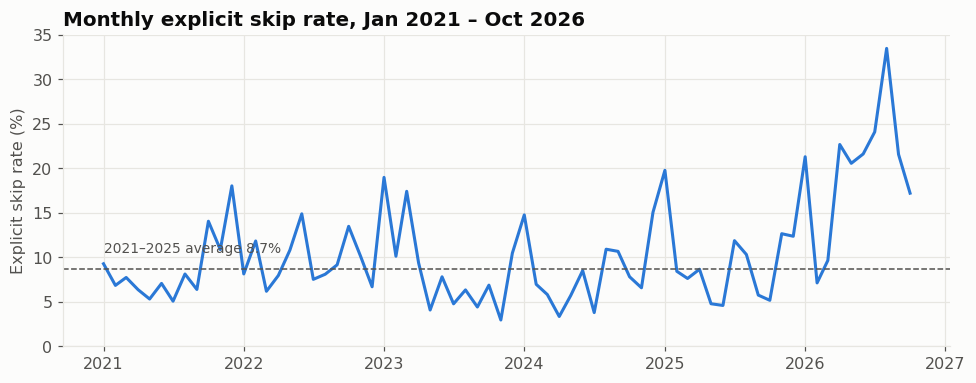

In [15]:
monthly = sql('''
    select date_trunc('month', event_date) as month,
           avg(is_explicit_skip::int)      as explicit_skip_rate
    from marts.marts_fct_stream_events
    where content_type = 'music'
      and event_date >= date '2021-01-01'
      and event_date <  date '2026-11-01'      -- drop the partial final month (export ends 10 Nov)
    group by 1 order by 1
''')
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(monthly.month, monthly.explicit_skip_rate * 100, color=BLUE, linewidth=2)
ax.axhline(base_rate * 100, color=INK2, linewidth=1, linestyle="--")
ax.text(monthly.month.iloc[0], base_rate * 100 + 1.8, f"2021–2025 average {base_rate:.1%}", color=INK2, fontsize=9)
ax.set_title("Monthly explicit skip rate, Jan 2021 – Oct 2026")
ax.set_ylabel("Explicit skip rate (%)"); ax.set_ylim(0, None)
save(fig, "q4_monthly_skip_rate")

**Finding.** The explicit skip rate rose from 8.7% (2021–2025) to 19.9% (2026), +11.2 points.
**62% of the increase is a mix effect:** skip-through sessions doubled from 5.8% to 11.5% of sessions.
**28% is a rate effect:** skipping rose within both segments (ordinary sessions 3.0% → 5.1%), and 10% is the interaction.

**What the data can't tell us:** the *cause*. A behaviour change (e.g. more browsing for new
music) and a logging change in the Spotify app would look identical in this export. Next step in a
real team: check whether the shift lines up with an app release date, and compare against other users' data.

## Summary

| Question | Method | Answer |
|---|---|---|
| Engagement trend | YoY with partial-year annualisation | Hours −30% from the 2023 peak, now flat; sessions only −9%, so sessions got shorter |
| What drives skips | Composition-controlled curve + clustered logistic regression | Fatigue drives both skip definitions (skip rate doubles over a session); shuffle and first listens change *how* I skip |
| Which artists stick | Monthly discovery cohorts, censoring-aware, chi-square | 16% retention after one first-month stream vs 68% after 10+ |
| 2026 skip spike | Shift-share decomposition | 62% mix (twice as many skip-through sessions), 28% rate, 10% interaction; root cause not identifiable from the data |

**Limitations.** One listener; observational data (associations, not causal effects); partial
2019/2026; possible app-version logging changes; "first listen" can't see plays before July 2019.